# 1 — Data gathering (development & external cohorts)

This notebook shows **how the cohort CSVs are built** from NHANES source files.

| Cohort | NHANES cycle | Source files | Output |
|--------|--------------|--------------|--------|
| **Development** | 2017–2020 | `DATA/P_*.xpt` | `RAW_ARTICLE.csv` |
| **External validation** | 2013–2014 | `DATA/EVAL_2013_2014/*_H.xpt` | `EVAL_2013_2014.csv` |

For each cohort we:

1. Read NHANES **SAS transport (`.xpt`)** files (or their CSV copies).
2. Keep the **19 article features** plus femoral-neck BMD (`DXXNKBMD`) and participant ID (`SEQN`).
3. **Merge** tables on `SEQN` and apply cohort-specific filters.

The reusable implementation lives in `experiment_utils.py` (`gather_development_cohort`, `gather_external_cohort`, `build_gathered_datasets`).

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from experiment_utils import (
    DEV_NHANES_DIR,
    DEV_NHANES_TABLES,
    EXT_NHANES_DIR,
    EXT_NHANES_TABLES,
    RAW_DEV_PATH,
    EXTERNAL_PATH,
    convert_xpt_directory_to_csv,
    gather_development_cohort,
    gather_external_cohort,
)

sns.set_theme(style='whitegrid', context='talk')
pd.set_option('display.max_columns', 30)

## 1.1 NHANES tables and the 19 features

Each NHANES component file contributes a subset of columns. Together they cover the 19 predictors from Xu et al. (2024) plus `DXXNKBMD` (for T-score / TARGET) and `OSQ060` (osteoporosis self-report, used in the TARGET rule but excluded from model predictors. Please see my article for this).

In [2]:
print('Development tables (2017–2020):')
for stem, cols in DEV_NHANES_TABLES.items():
    print(f'  {stem}: {cols}')

print('\nExternal tables (2013–2014):')
for stem, cols in EXT_NHANES_TABLES.items():
    print(f'  {stem}: {cols}')

Development tables (2017–2020):
  P_DXXFEM: ['SEQN', 'DXXNKBMD']
  P_DEMO: ['SEQN', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR']
  P_BMX: ['SEQN', 'BMXBMI']
  P_BIOPRO: ['SEQN', 'LBXSCK', 'LBDSCHSI', 'LBXSAPSI', 'LBXSUA', 'LBDSTPSI', 'LBDSGBSI', 'LBXSOSSI']
  P_GHB: ['SEQN', 'LBXGH']
  P_CBC: ['SEQN', 'LBXMCVSI', 'LBXRDW', 'LBXNEPCT', 'LBXMOPCT']
  P_DIQ: ['SEQN', 'DIQ010']
  P_OSQ: ['SEQN', 'OSQ060', 'OSQ150']

External tables (2013–2014):
  DEMO_H: ['SEQN', 'RIDAGEYR', 'RIAGENDR', 'INDFMPIR']
  BMX_H: ['SEQN', 'BMXBMI']
  DXXFEM_H: ['SEQN', 'DXXNKBMD']
  BIOPRO_H: ['SEQN', 'LBXSCK', 'LBDSCHSI', 'LBXSAPSI', 'LBXSUA', 'LBDSTPSI', 'LBDSGBSI', 'LBXSOSSI']
  GHB_H: ['SEQN', 'LBXGH']
  DIQ_H: ['SEQN', 'DIQ010']
  CBC_H: ['SEQN', 'LBXMCVSI', 'LBXRDW', 'LBXNEPCT', 'LBXMOPCT']
  OSQ_H: ['SEQN', 'OSQ060', 'OSQ150']


## 1.2 Optional: convert `.xpt` → CSV

NHANES distributes SAS transport files (`.xpt`). We read them directly with `pd.read_sas`, but can also write CSV copies alongside the originals for inspection.

In [3]:
# CSV copies are written only when missing (overwrite=False).
dev_csv = convert_xpt_directory_to_csv(DEV_NHANES_DIR)
ext_csv = convert_xpt_directory_to_csv(EXT_NHANES_DIR)

print(f'Development: {len(dev_csv)} tables in {DEV_NHANES_DIR}')
print(f'External:    {len(ext_csv)} tables in {EXT_NHANES_DIR}')
list(dev_csv)[:3]

Development: 8 tables in /Users/vassilis/Documents/OP_article/DATA
External:    8 tables in /Users/vassilis/Documents/OP_article/DATA/EVAL_2013_2014


['P_BIOPRO', 'P_BMX', 'P_CBC']

## 1.3 Merge NHANES tables on `SEQN`

- **Development:** outer join (retain all participants present in any component file), then age ≥ 50 and non-missing femoral-neck BMD.
- **External:** inner join (participants must appear in every component file).

In [4]:
df_dev = gather_development_cohort(verbose=False)
df_ext_merged = gather_external_cohort(finalize=False, verbose=False)

print(f'Development gathered: {df_dev.shape[0]} rows × {df_dev.shape[1]} cols')
print(f'External merged (pre-finalize): {df_ext_merged.shape[0]} rows × {df_ext_merged.shape[1]} cols')
df_dev.head()

Development gathered: 3545 rows × 21 cols
External merged (pre-finalize): 3708 rows × 21 cols


,SEQN,DXXNKBMD,RIDAGEYR,RIAGENDR,INDFMPIR,BMXBMI,LBXSCK,LBDSCHSI,LBXSAPSI,LBXSUA,LBDSTPSI,LBDSGBSI,LBXSOSSI,LBXGH,LBXMCVSI,LBXRDW,LBXNEPCT,LBXMOPCT,DIQ010,OSQ060,OSQ150
0,109274.0,0.831,68.0,1.0,1.20,30.2,93.0,2.715,49.0,5.1,68.0,28.0,278.0,5.7,92.3,13.9,67.3,12.5,1.0,2.0,2.0
1,109282.0,0.661,76.0,1.0,3.61,26.6,112.0,6.181,74.0,6.9,71.0,28.0,290.0,5.5,91.2,14.5,65.4,7.6,2.0,2.0,2.0
2,109292.0,0.886,58.0,1.0,1.60,30.5,250.0,4.448,49.0,7.6,69.0,30.0,283.0,6.4,93.6,13.2,60.8,6.9,1.0,2.0,2.0
3,109300.0,0.540,54.0,2.0,5.00,29.6,152.0,5.120,84.0,4.7,73.0,31.0,286.0,5.4,87.6,13.0,55.6,8.0,2.0,2.0,2.0
4,109305.0,0.736,55.0,1.0,5.00,20.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.2,87.3,12.8,57.9,7.5,2.0,2.0,2.0


## 1.4 Finalize external cohort → `EVAL_2013_2014.csv`

The external file adds T-score / TARGET and keeps complete cases. Development output stops at the raw merged stage. Cleaning for modeling happens in `2_DATA_CLEANING.ipynb`.

In [5]:
df_ext = gather_external_cohort(finalize=True)

print('--- External validation set ---')
print(f'Participants: {len(df_ext)}')
print(f'Low BMD cases (TARGET=1): {df_ext["TARGET"].sum()}')
print(f'TARGET prevalence: {df_ext["TARGET"].mean():.3f}')

# Sanity check against files already on disk
saved_dev = pd.read_csv(RAW_DEV_PATH)
saved_ext = pd.read_csv(EXTERNAL_PATH)
print(f'\nMatches saved development CSV: {df_dev.shape == saved_dev.shape}')
print(f'Matches saved external CSV:     {df_ext.shape == saved_ext.shape}')

--- External validation set ---
Participants: 1728
Low BMD cases (TARGET=1): 850
TARGET prevalence: 0.492

Matches saved development CSV: True
Matches saved external CSV:     True


## 1.5 Missingness snapshot (development, before cleaning)

The development cohort intentionally retains rows with missing predictors; they are dropped later in complete-case cleaning.

Columns with missing values:
INDFMPIR    13.6%
LBXSCK       6.3%
LBXSAPSI     6.2%
LBDSTPSI     6.2%
LBDSCHSI     6.2%
LBXSUA       6.2%
LBDSGBSI     6.2%
LBXSOSSI     6.2%
LBXGH        3.6%
LBXMOPCT     3.1%
LBXNEPCT     3.1%
LBXRDW       3.1%
LBXMCVSI     3.1%
BMXBMI       0.5%
OSQ060       0.0%
OSQ150       0.0%
dtype: object


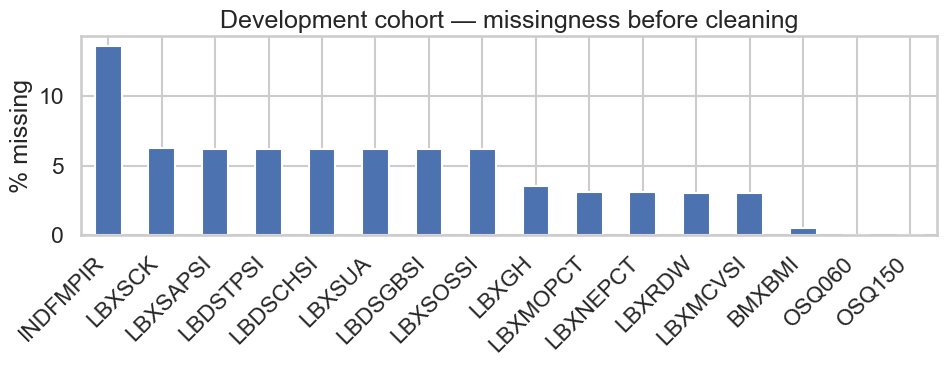

In [6]:
miss = df_dev.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
print('Columns with missing values:')
print((miss * 100).round(1).astype(str) + '%')

plt.figure(figsize=(10, 4))
(miss * 100).plot(kind='bar')
plt.ylabel('% missing')
plt.title('Development cohort — missingness before cleaning')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---

**Next step:** `2_DATA_CLEANING.ipynb` applies invalid-code cleaning on the development cohort, computes T-score / TARGET, and keeps **complete cases only**.

To regenerate both CSVs from source in one call: `build_gathered_datasets(save=True, overwrite=True)` in `experiment_utils.py`.